# Filter comparison: Bloom vs Ribbon vs Cuckoo in RocksDB

Analysis of the results produced by `harness.py` (`results/results.csv`, one row
per measured run, and `results/filters.csv`, one row per filter rebuild).

* Every configuration uses the **same base DB** (10M keys, P1 LSM settings); only
  the filter blocks differ, verified per level by the harness.
* Each run is a warm-up pass, `resetstats`, then a measured pass of 200K lookups
  per thread. Each configuration was measured **3 times**; plots show the mean,
  and error bars show ±1 standard deviation across repeats.
* **Ribbon names use Bloom-equivalent bits**: `ribbon-10` targets the FP rate of a
  10 bits/key Bloom filter and uses about 7.2 real bits/key. Plots of memory use
  **real** bits/key from `filters.csv`.

Run top to bottom. Figures are also written to `figures/` (PNG and PDF). The last
section has helpers for poking around.

## Setup

In [1]:
%matplotlib inline
from pathlib import Path
import math

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from IPython.display import display

RESULTS = Path("results")          # relative to this notebook (filter_project/)
FIGURES = Path("figures")
SAVE_FIGURES = True                # set False while experimenting
FIGURES.mkdir(exist_ok=True)

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)

In [2]:
# One hue per filter TYPE (identity follows the type, never its rank). Bit-level
# variants of the same type share the hue and differ by line style. Markers are a
# second, color-independent encoding. "none" is a neutral gray baseline.
COLORS  = {"bloom": "#2a78d6", "ribbon": "#eb6834", "cuckoo": "#1baf7a", "none": "#898781"}
MARKERS = {"bloom": "o", "ribbon": "s", "cuckoo": "^", "none": "D"}
NAMES   = {"bloom": "Bloom", "ribbon": "Ribbon", "cuckoo": "Cuckoo", "none": "No filter"}
INK, INK2, MUTED = "#0b0b0b", "#52514e", "#898781"
GRID, AXIS, SURFACE = "#e1e0d9", "#c3c2b7", "#fcfcfb"

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": AXIS, "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "grid.linestyle": "-",
    "axes.axisbelow": True,
    "axes.labelcolor": INK2, "axes.labelsize": 9.5,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.titlecolor": INK,
    "xtick.color": AXIS, "ytick.color": AXIS,
    "xtick.labelcolor": INK2, "ytick.labelcolor": INK2,
    "xtick.labelsize": 9, "ytick.labelsize": 9,
    "text.color": INK, "legend.fontsize": 9, "legend.frameon": False,
    "lines.linewidth": 2, "lines.markersize": 6,
    "font.family": "sans-serif",
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
})


def ftype(name):
    return name.split("-")[0]


def plot_series(ax, x, y, yerr, name, label=None, ls="-"):
    """One series: thin line, marker with a surface-colored ring, thin error bars."""
    t = ftype(name)
    ax.errorbar(x, y, yerr=yerr, color=COLORS[t], marker=MARKERS[t], linestyle=ls,
                markeredgecolor=SURFACE, markeredgewidth=1.2, capsize=0, elinewidth=1,
                label=label if label is not None else name)


def label_ends(ax, ends, min_gap_pt=11):
    """Direct-label line ends (text in ink, beside the line's last point), nudging
    labels apart vertically so they never overlap. ends: [(x, y, text)]."""
    fig = ax.figure
    fig.canvas.draw()
    to_pt = 72.0 / fig.dpi
    pts = sorted(((ax.transData.transform((x, y))[1] * to_pt, x, y, t)
                  for x, y, t in ends), key=lambda p: p[0])
    # Greedy upward placement, then shift each run of touching labels so it
    # is centered on its lines (keeps labels next to their points)
    placed = []
    for y_pt, *_ in pts:
        placed.append(y_pt if not placed else max(y_pt, placed[-1] + min_gap_pt))
    i = 0
    while i < len(pts):
        j = i
        while j + 1 < len(pts) and placed[j + 1] - placed[j] <= min_gap_pt + 1e-6:
            j += 1
        shift = (sum(p[0] for p in pts[i:j + 1]) - sum(placed[i:j + 1])) / (j - i + 1)
        for k in range(i, j + 1):
            placed[k] += shift
        i = j + 1
    for (y_pt, x, y, text), target in zip(pts, placed):
        ax.annotate(text, (x, y), xytext=(7, target - y_pt), textcoords="offset points",
                    va="center", ha="left", fontsize=8.5, color=INK2,
                    annotation_clip=False)


def kfmt(v, _pos=None):
    if v >= 1e6:
        return f"{v / 1e6:.3g}M"
    if v >= 1e3:
        return f"{v / 1e3:.3g}K"
    return f"{v:.3g}"


def save(fig, name):
    if SAVE_FIGURES:
        for ext in ("png", "pdf"):
            fig.savefig(FIGURES / f"{name}.{ext}")


def summarize(df, by, metrics):
    """Mean, std and count across repeats for each group."""
    g = df.groupby(by, dropna=False)[metrics]
    out = g.mean().add_suffix("_mean").join(g.std().add_suffix("_std"))
    return out.join(g.size().rename("n")).reset_index()

## Load and sanity-check

In [3]:
results = pd.read_csv(RESULTS / "results.csv")
filters = pd.read_csv(RESULTS / "filters.csv").drop_duplicates("filter", keep="last")

results["ftype"] = results["filter"].map(ftype)
results["bits_actual"] = results["filter_bits_per_key_actual"]
results["empty_fraction"] = 1.0 - results["expected_found_fraction"]
results["num_keys"] = results["command"].str.extract(r"-num=(\d+)", expand=False).astype(int)
# Per-lookup block cache misses. (The *ratios* in the CSV can mislead: with good
# filters there are very few index lookups, so a handful of cold misses
# dominates the ratio. Misses per lookup is what costs time.)
for kind in ("filter", "index", "data"):
    results[f"{kind}_misses_per_lookup"] = results[f"bc_{kind}_miss"] / results["lookups"]

print(f"{len(results)} runs, {results['experiment'].nunique()} experiments, "
      f"{results['filter'].nunique()} filter configurations")
display(results.groupby("experiment").size().rename("runs").to_frame())

# Everything should come from one dataset, one build and one machine
for col in ("num_keys", "db_bench_version", "host"):
    vals = pd.Series(results[col].unique()).tolist()
    print(f"{col:17s} {vals}" + ("" if len(vals) == 1 else "   <-- MIXED: check before comparing"))
bad_found = (results["found_fraction"] - results["expected_found_fraction"]).abs() > 0.03
print(f"runs with an unexpected found fraction: {int(bad_found.sum())}")

444 runs, 5 experiments, 20 filter configurations


,runs
experiment,
E1_bits_per_key,114
E2_memory_pressure,96
E3_empty_fraction,90
E4_skew,36
E5_threads,108


num_keys          [10000000]
db_bench_version  ['c2b11946a']
host              ['third-workstation']
runs with an unexpected found fraction: 0


In [4]:
# Run-to-run noise: coefficient of variation of throughput across the 3 repeats
keys = ["experiment", "filter", "params_no_repeat"]
results["params_no_repeat"] = results["params"]
cv = (results.groupby(keys)["ops_per_sec"].agg(["mean", "std", "count"])
      .assign(cv=lambda d: d["std"] / d["mean"]))
print("Throughput CV across repeats:", cv["cv"].describe(percentiles=[.5, .9]).round(3).to_dict())
noisy = cv[cv["cv"] > 0.10].sort_values("cv", ascending=False)
print(f"{len(noisy)} configurations with CV > 10% (treat their differences with care):")
display(noisy.reset_index()[["experiment", "filter", "params_no_repeat", "mean", "cv"]]
        .assign(params_no_repeat=lambda d: d["params_no_repeat"].str.slice(0, 120)))

Throughput CV across repeats: {'count': 148.0, 'mean': 0.035, 'std': 0.048, 'min': 0.001, '50%': 0.015, '90%': 0.096, 'max': 0.319}
15 configurations with CV > 10% (treat their differences with care):


,experiment,filter,params_no_repeat,mean,cv
0,E3_empty_fraction,bloom-16,"{""cache_high_pri_pool_ratio"": 0.5, ""cache_nums...",19142.666667,0.318886
1,E1_bits_per_key,none,"{""cache_high_pri_pool_ratio"": 0.5, ""cache_nums...",4163.333333,0.203339
2,E1_bits_per_key,none,"{""cache_high_pri_pool_ratio"": 0.5, ""cache_nums...",3098.000000,0.187574
3,E1_bits_per_key,cuckoo-10,"{""cache_high_pri_pool_ratio"": 0.5, ""cache_nums...",10226.333333,0.164320
4,E1_bits_per_key,bloom-6,"{""cache_high_pri_pool_ratio"": 0.5, ""cache_nums...",8917.000000,0.161644
5,E2_memory_pressure,bloom-10,"{""cache_high_pri_pool_ratio"": 0.5, ""cache_nums...",87238.666667,0.159830
6,E3_empty_fraction,none,"{""cache_high_pri_pool_ratio"": 0.5, ""cache_nums...",3197.666667,0.129383
7,E1_bits_per_key,cuckoo-20,"{""cache_high_pri_pool_ratio"": 0.5, ""cache_nums...",10746.666667,0.122954
8,E5_threads,bloom-10,"{""cache_high_pri_pool_ratio"": 0.5, ""cache_nums...",12524.666667,0.122024
9,E5_threads,ribbon-10,"{""cache_high_pri_pool_ratio"": 0.5, ""cache_nums...",458292.666667,0.121905


### Filter memory (from the rebuilds)

In [5]:
mem = (filters.assign(ftype=filters["filter"].map(ftype),
                      filter_MiB=filters["filter_bytes_total"] / 2**20)
       [["filter", "ftype", "filter_bits_config", "filter_bits_per_key_actual",
         "filter_MiB", "rebuild_seconds"]]
       .sort_values(["ftype", "filter_bits_per_key_actual"]))
display(mem.style.format({"filter_bits_per_key_actual": "{:.2f}", "filter_MiB": "{:.1f}",
                          "rebuild_seconds": "{:.0f}"}).hide(axis="index"))

filter,ftype,filter_bits_config,filter_bits_per_key_actual,filter_MiB,rebuild_seconds
bloom-6,bloom,6.000000,6.20,7.4,154
bloom-8,bloom,8.000000,8.20,9.8,154
bloom-10,bloom,10.000000,10.20,12.2,156
bloom-12,bloom,12.000000,12.19,14.5,155
bloom-16,bloom,16.000000,16.18,19.3,154
bloom-20,bloom,20.000000,20.17,24.0,153
cuckoo-6,cuckoo,6.000000,6.04,7.2,153
cuckoo-8,cuckoo,8.000000,8.04,9.6,154
cuckoo-10,cuckoo,10.000000,10.04,12.0,155
cuckoo-12,cuckoo,12.000000,12.04,14.4,155


Rebuild time is dominated by rewriting ~5 GB of data, so it does **not** isolate
filter construction cost; `filter_bench` measures that (Bloom ≈ 35, Cuckoo ≈ 52,
Ribbon ≈ 130 ns/key in earlier runs).

## E1: bits per key

19 configurations (`none`, and each filter at 6–20 configured bits/key), with
lookups for absent keys (`empty`, `readmissing`) and existing keys (`nonempty`,
`readrandom`). The 256 MB cache holds all filter and index blocks.

### False-positive rate vs memory
Dotted lines are models: the standard Bloom filter formula with the optimal number
of hash functions, and the cuckoo filter's sizing rule from `cuckoo_filter_policy.cc`
(fingerprint bits f = ⌊0.95·b⌋, load f/b, FPR ≈ 1 − (1 − 1/(2^f − 1))^(8·load)).

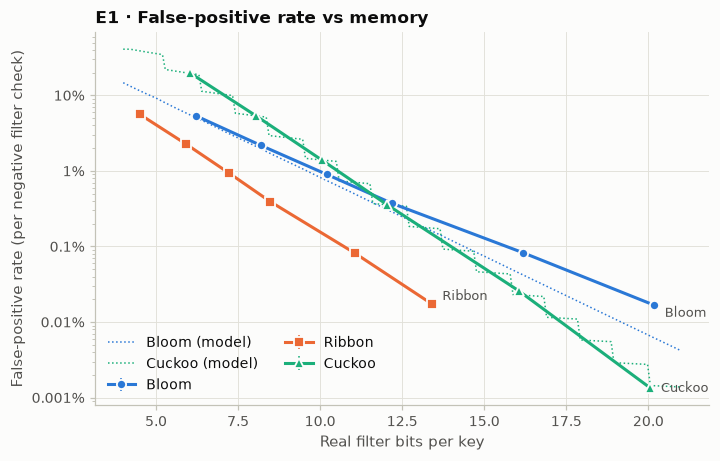

filter,Bloom,Cuckoo,Ribbon
configured bits,,,
6.000000,5.386%,19.727%,5.588%
8.000000,2.170%,5.376%,2.247%
10.000000,0.901%,1.399%,0.928%
12.000000,0.372%,0.356%,0.391%
16.000000,0.083%,0.026%,0.082%
20.000000,0.017%,0.001%,0.017%


In [6]:
def bloom_fpr_model(b):
    k = max(1, round(b * math.log(2)))
    return (1 - math.exp(-k / b)) ** k


def cuckoo_fpr_model(b):
    f = min(32, max(4, math.floor(0.95 * b)))
    load = min(0.95, f / b)
    return 1 - (1 - 1 / (2 ** f - 1)) ** (8 * load)


e1 = results[results["experiment"] == "E1_bits_per_key"]
# FPR is a property of the filter; use the empty workload (most negative checks)
fpr = summarize(e1[(e1["workload"] == "empty") & (e1["ftype"] != "none")],
                ["ftype", "filter", "bits_actual"], ["fpr"]).sort_values("bits_actual")

fig, ax = plt.subplots(figsize=(7.2, 4.4))
ends = []
for t in ("bloom", "ribbon", "cuckoo"):
    d = fpr[fpr["ftype"] == t]
    plot_series(ax, d["bits_actual"], d["fpr_mean"], d["fpr_std"], t, label=NAMES[t])
    last = d.iloc[-1]
    ends.append((last["bits_actual"], last["fpr_mean"], NAMES[t]))
bb = np.linspace(4, 21, 200)
ax.plot(bb, [bloom_fpr_model(b) for b in bb], color=COLORS["bloom"], lw=1, ls=":",
        label="Bloom (model)")
ax.plot(bb, [cuckoo_fpr_model(b) for b in bb], color=COLORS["cuckoo"], lw=1, ls=":",
        label="Cuckoo (model)")
ax.set_yscale("log")
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{100 * v:g}%"))
ax.set_xlabel("Real filter bits per key")
ax.set_ylabel("False-positive rate (per negative filter check)")
ax.set_title("E1 · False-positive rate vs memory")
ax.legend(loc="lower left", ncol=2)
label_ends(ax, ends)
save(fig, "e1_fpr_vs_bits")
plt.show()

table = fpr.assign(fpr_pct=100 * fpr["fpr_mean"])[["filter", "bits_actual", "fpr_pct"]]
display(table.pivot_table(index=table["filter"].str.split("-").str[1].astype(float).rename("configured bits"),
                          columns=table["filter"].map(ftype), values="fpr_pct").round(4)
        .rename(columns=NAMES).style.format("{:.3f}%").set_caption("FPR (%) by configured bits/key"))

### Lookup throughput and latency vs memory
`No filter` is shown as a gray reference line (it has 0 bits/key).

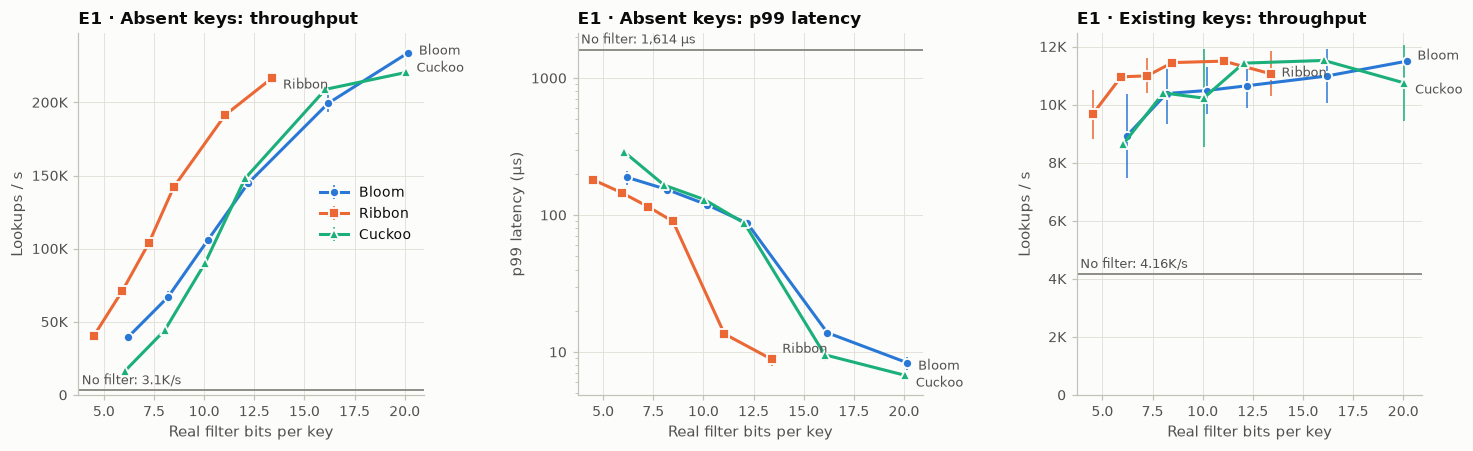

Filter checks per lookup (same for every filter, since the DB shape is identical):


,filter_checks_per_lookup_mean
workload,
empty,4.475
nonempty,3.710


In [7]:
e1s = summarize(e1, ["workload", "ftype", "filter", "bits_actual"],
                ["ops_per_sec", "p99_us", "data_misses_per_lookup", "filter_checks_per_lookup"])

fig, axes = plt.subplots(1, 3, figsize=(13.5, 4.2))
panels = [("empty", "ops_per_sec", "Absent keys: throughput", "Lookups / s"),
          ("empty", "p99_us", "Absent keys: p99 latency", "p99 latency (µs)"),
          ("nonempty", "ops_per_sec", "Existing keys: throughput", "Lookups / s")]
for ax, (wl, metric, title, ylabel) in zip(axes, panels):
    d = e1s[e1s["workload"] == wl]
    ends = []
    for t in ("bloom", "ribbon", "cuckoo"):
        s = d[d["ftype"] == t].sort_values("bits_actual")
        plot_series(ax, s["bits_actual"], s[f"{metric}_mean"], s[f"{metric}_std"], t, label=NAMES[t])
        ends.append((s["bits_actual"].iloc[-1], s[f"{metric}_mean"].iloc[-1], NAMES[t]))
    base = d[d["ftype"] == "none"][f"{metric}_mean"].iloc[0]
    ax.axhline(base, color=COLORS["none"], lw=1.2)
    base_txt = f"{base:,.0f} µs" if metric == "p99_us" else f"{kfmt(base)}/s"
    ax.annotate(f"No filter: {base_txt}", (0.01, base), xycoords=("axes fraction", "data"),
                xytext=(0, 4), textcoords="offset points", fontsize=8.5, color=INK2)
    if metric == "p99_us":
        ax.set_yscale("log")
        ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{v:g}"))
    else:
        ax.set_ylim(bottom=0)
        ax.yaxis.set_major_formatter(mticker.FuncFormatter(kfmt))
    ax.set_title(f"E1 · {title}")
    ax.set_xlabel("Real filter bits per key")
    ax.set_ylabel(ylabel)
    label_ends(ax, ends)
axes[0].legend(loc="center right")
fig.tight_layout(w_pad=3)
save(fig, "e1_throughput_latency")
plt.show()

print("Filter checks per lookup (same for every filter, since the DB shape is identical):")
display(e1s.groupby("workload")["filter_checks_per_lookup_mean"].max().round(3).to_frame())

### What sets throughput for absent keys? False positives.
Each false positive costs a data block read from disk. If that dominates, then
microseconds per lookup ≈ *a* + *b* × (data block reads per lookup), for **every**
filter type alike, and filter CPU cost is a second-order effect. The fit below uses
the filter configurations only; `No filter` is shown as an out-of-sample check.

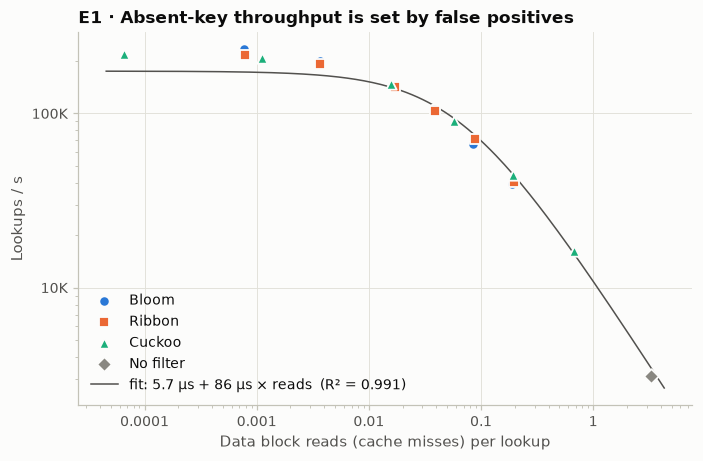

Fit: 5.7 µs per lookup + 86 µs per data block read (R² = 0.991)
No filter: predicted 3,437 lookups/s, measured 3,098


In [8]:
d = e1s[(e1s["workload"] == "empty")].copy()
d["us_per_lookup"] = 1e6 / d["ops_per_sec_mean"]
fit = d[d["ftype"] != "none"]
b, a = np.polyfit(fit["data_misses_per_lookup_mean"], fit["us_per_lookup"], 1)
pred = a + b * fit["data_misses_per_lookup_mean"]
r2 = 1 - ((fit["us_per_lookup"] - pred) ** 2).sum() / ((fit["us_per_lookup"] - fit["us_per_lookup"].mean()) ** 2).sum()

fig, ax = plt.subplots(figsize=(7.2, 4.4))
for t in ("bloom", "ribbon", "cuckoo", "none"):
    s = d[d["ftype"] == t]
    ax.scatter(s["data_misses_per_lookup_mean"], s["ops_per_sec_mean"], s=46,
               color=COLORS[t], marker=MARKERS[t], edgecolor=SURFACE, linewidth=1.2,
               label=NAMES[t], zorder=3)
xs = np.logspace(np.log10(d["data_misses_per_lookup_mean"].min() * 0.7),
                 np.log10(d["data_misses_per_lookup_mean"].max() * 1.3), 200)
ax.plot(xs, 1e6 / (a + b * xs), color=INK2, lw=1, zorder=2,
        label=f"fit: {a:.1f} µs + {b:.0f} µs × reads  (R² = {r2:.3f})")
ax.set_xscale("log")
ax.set_yscale("log")
ax.yaxis.set_major_formatter(mticker.FuncFormatter(kfmt))
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{v:g}"))
ax.set_xlabel("Data block reads (cache misses) per lookup")
ax.set_ylabel("Lookups / s")
ax.set_title("E1 · Absent-key throughput is set by false positives")
ax.legend(loc="lower left")
save(fig, "e1_false_positives_explain_throughput")
plt.show()

none_row = d[d["ftype"] == "none"].iloc[0]
print(f"Fit: {a:.1f} µs per lookup + {b:.0f} µs per data block read (R² = {r2:.3f})")
print(f"No filter: predicted {1e6 / (a + b * none_row['data_misses_per_lookup_mean']):,.0f} lookups/s, "
      f"measured {none_row['ops_per_sec_mean']:,.0f}")

## E2: memory pressure

Filter, index and data blocks share the block cache
(`cache_index_and_filter_blocks=true`). `ribbon-10` has Bloom-10's FP rate in ~30%
less memory; `ribbon-14.3` has Bloom-10's memory with a much lower FP rate.

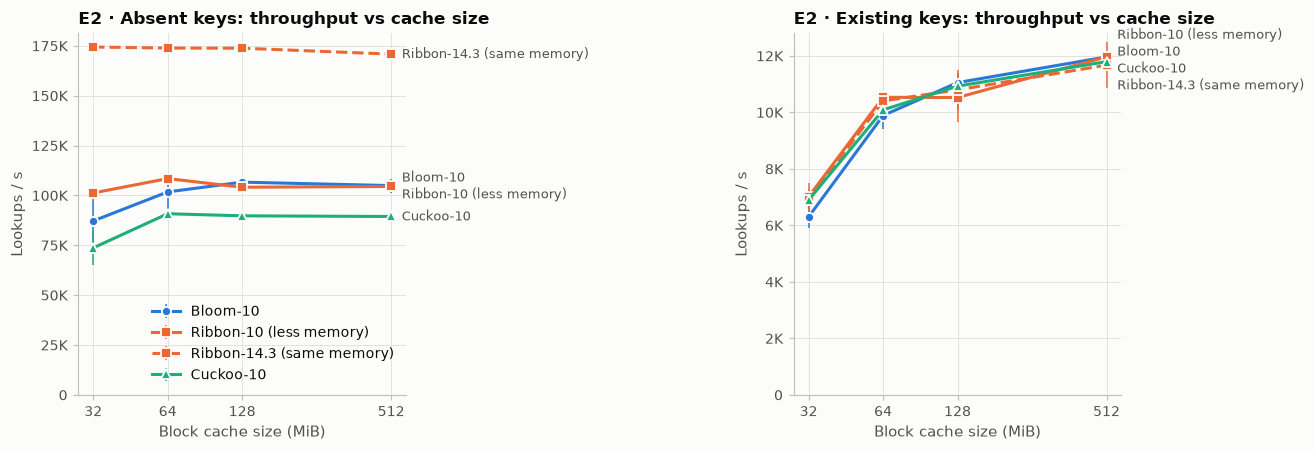

In [9]:
e2 = results[results["experiment"] == "E2_memory_pressure"].copy()
e2["cache_MiB"] = e2["cache_size"] / 2**20
e2s = summarize(e2, ["workload", "filter", "cache_MiB"],
                ["ops_per_sec", "p99_us", "filter_misses_per_lookup",
                 "index_misses_per_lookup", "data_misses_per_lookup"])
E2_ORDER = ["bloom-10", "ribbon-10", "ribbon-14.3", "cuckoo-10"]
E2_STYLE = {"ribbon-14.3": "--"}
E2_LABEL = {"bloom-10": "Bloom-10", "ribbon-10": "Ribbon-10 (less memory)",
            "ribbon-14.3": "Ribbon-14.3 (same memory)", "cuckoo-10": "Cuckoo-10"}


def cache_axis(ax):
    ax.set_xscale("log", base=2)
    ax.set_xticks(sorted(e2s["cache_MiB"].unique()))
    ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{v:g}"))
    ax.xaxis.set_minor_locator(mticker.NullLocator())
    ax.set_xlabel("Block cache size (MiB)")


fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
for ax, wl, title in zip(axes, ("empty", "nonempty"), ("Absent keys", "Existing keys")):
    d = e2s[e2s["workload"] == wl]
    ends = []
    for name in E2_ORDER:
        s = d[d["filter"] == name].sort_values("cache_MiB")
        plot_series(ax, s["cache_MiB"], s["ops_per_sec_mean"], s["ops_per_sec_std"], name,
                    label=E2_LABEL[name], ls=E2_STYLE.get(name, "-"))
        ends.append((s["cache_MiB"].iloc[-1], s["ops_per_sec_mean"].iloc[-1], E2_LABEL[name]))
    cache_axis(ax)
    ax.set_ylim(bottom=0)
    ax.yaxis.set_major_formatter(mticker.FuncFormatter(kfmt))
    ax.set_ylabel("Lookups / s")
    ax.set_title(f"E2 · {title}: throughput vs cache size")
    label_ends(ax, ends)
axes[0].legend(loc="lower right")
fig.tight_layout(w_pad=10)
save(fig, "e2_throughput_vs_cache")
plt.show()

Where the time goes for existing keys: block cache misses per lookup by block type.
Bloom-10, Cuckoo-10 and Ribbon-14.3 have nearly the same filter size, so their lines
overlap; Ribbon-10 (smallest filters) is the one that separates.

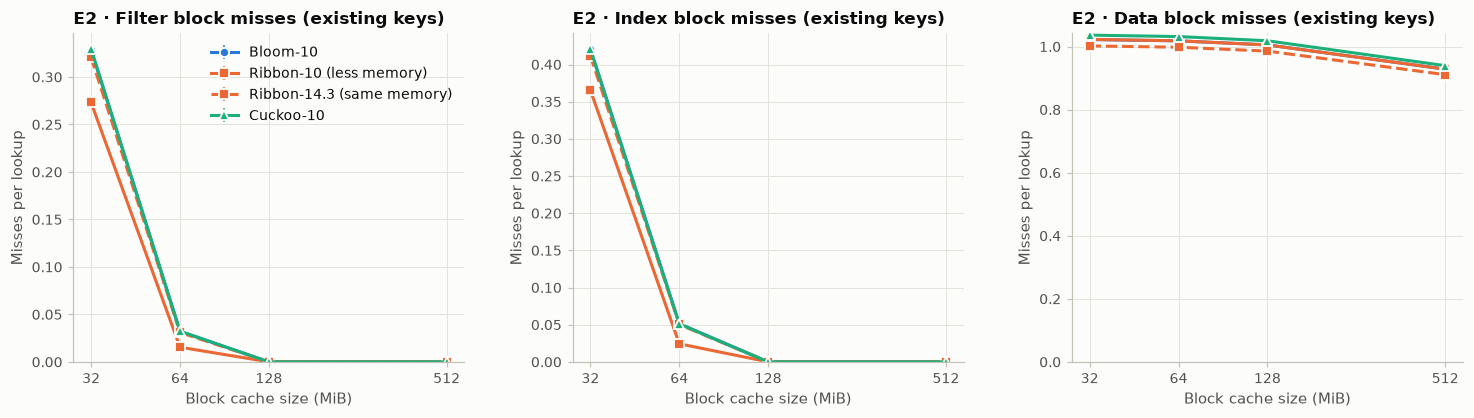

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(13.5, 3.9), sharey=False)
d = e2s[e2s["workload"] == "nonempty"]
for ax, kind in zip(axes, ("filter", "index", "data")):
    for name in E2_ORDER:
        s = d[d["filter"] == name].sort_values("cache_MiB")
        plot_series(ax, s["cache_MiB"], s[f"{kind}_misses_per_lookup_mean"],
                    s[f"{kind}_misses_per_lookup_std"], name, label=E2_LABEL[name],
                    ls=E2_STYLE.get(name, "-"))
    cache_axis(ax)
    ax.set_ylim(bottom=0)
    ax.set_ylabel("Misses per lookup")
    ax.set_title(f"E2 · {kind.capitalize()} block misses (existing keys)")
axes[0].legend(loc="upper right")
fig.tight_layout(w_pad=3)
save(fig, "e2_cache_misses_by_block_type")
plt.show()

display(e2s.pivot_table(index=["workload", "cache_MiB"], columns="filter",
                        values="ops_per_sec_mean")[E2_ORDER].round(0)
        .style.format("{:,.0f}").set_caption("E2 · mean lookups/s"))

## E3: fraction of lookups for absent keys

Absent keys sort *between* existing keys (`-read_missing_fraction`), so only a filter
(or reading the data block) can rule them out. Solid lines are 10 bits/key, dashed
lines 16 bits/key. Log scale: throughput spans almost two orders of magnitude.

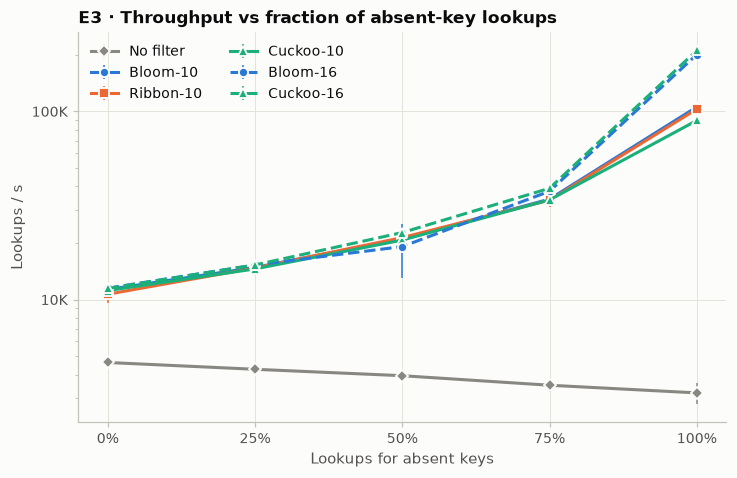

filter,bloom-10,ribbon-10,cuckoo-10,bloom-16,cuckoo-16
empty_fraction,,,,,
0% absent,2.4×,2.3×,2.4×,2.5×,2.5×
25% absent,3.5×,3.5×,3.4×,3.6×,3.6×
50% absent,5.3×,5.4×,5.3×,4.9×,5.8×
75% absent,9.7×,9.6×,9.7×,10.7×,11.1×
100% absent,33.0×,32.2×,28.0×,62.7×,65.9×


In [11]:
e3 = results[results["experiment"] == "E3_empty_fraction"]
e3s = summarize(e3, ["filter", "empty_fraction"], ["ops_per_sec", "p99_us"])
E3_ORDER = ["none", "bloom-10", "ribbon-10", "cuckoo-10", "bloom-16", "cuckoo-16"]
E3_LABEL = {"none": "No filter", "bloom-10": "Bloom-10", "ribbon-10": "Ribbon-10",
            "cuckoo-10": "Cuckoo-10", "bloom-16": "Bloom-16", "cuckoo-16": "Cuckoo-16"}

fig, ax = plt.subplots(figsize=(7.6, 4.6))
for name in E3_ORDER:
    s = e3s[e3s["filter"] == name].sort_values("empty_fraction")
    plot_series(ax, 100 * s["empty_fraction"], s["ops_per_sec_mean"], s["ops_per_sec_std"],
                name, label=E3_LABEL[name], ls="--" if name.endswith("-16") else "-")
ax.set_yscale("log")
ax.yaxis.set_major_formatter(mticker.FuncFormatter(kfmt))
ax.set_xticks([0, 25, 50, 75, 100])
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{v:g}%"))
ax.set_xlabel("Lookups for absent keys")
ax.set_ylabel("Lookups / s")
ax.set_title("E3 · Throughput vs fraction of absent-key lookups")
ax.legend(loc="upper left", ncol=2)
save(fig, "e3_throughput_vs_empty_fraction")
plt.show()

piv = e3s.pivot_table(index="empty_fraction", columns="filter", values="ops_per_sec_mean")[E3_ORDER]
display(piv.div(piv["none"], axis=0).drop(columns="none").round(1)
        .rename(index=lambda v: f"{100 * v:g}% absent")
        .style.format("{:.1f}×").set_caption("E3 · speedup over no filter"))

## E4: skewed lookups

`read_random_exp_range` concentrates lookups on low-numbered keys (0 = uniform,
higher = more skewed); half the lookups are for absent keys and the cache is 64 MB.
This is the baseline for a hotness-aware filter such as ElasticBF.

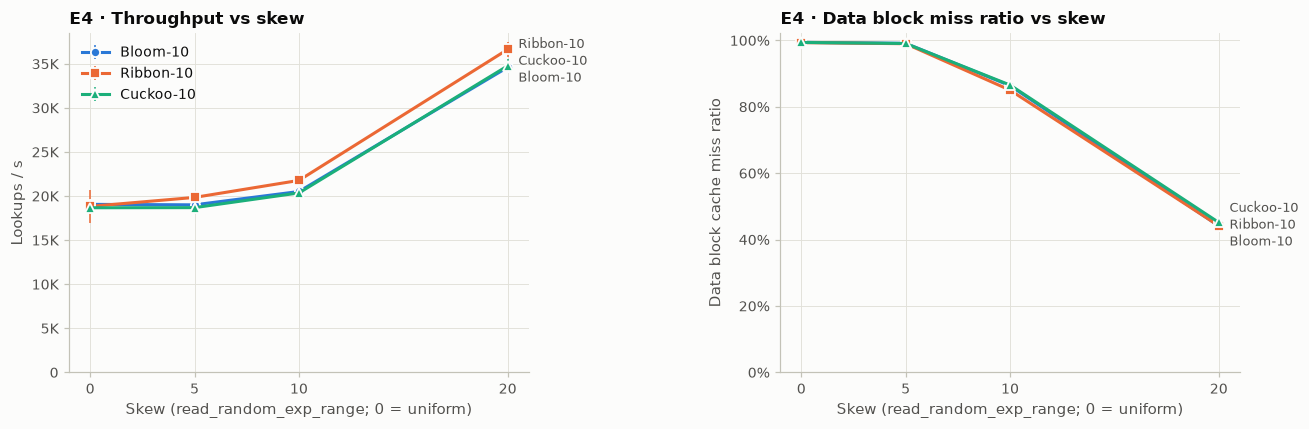

filter,bloom-10,cuckoo-10,ribbon-10
read_random_exp_range,,,
0,0.908%,1.399%,0.924%
5,0.895%,1.382%,0.952%
10,0.916%,1.350%,0.933%
20,0.978%,1.142%,0.693%


In [12]:
e4 = results[results["experiment"] == "E4_skew"]
e4s = summarize(e4, ["filter", "read_random_exp_range"],
                ["ops_per_sec", "bc_data_miss_ratio", "fpr"])
fig, axes = plt.subplots(1, 2, figsize=(12, 4.0))
for ax, metric, title, ylabel in [
        (axes[0], "ops_per_sec", "Throughput vs skew", "Lookups / s"),
        (axes[1], "bc_data_miss_ratio", "Data block miss ratio vs skew", "Data block cache miss ratio")]:
    ends = []
    for name in ("bloom-10", "ribbon-10", "cuckoo-10"):
        s = e4s[e4s["filter"] == name].sort_values("read_random_exp_range")
        plot_series(ax, s["read_random_exp_range"], s[f"{metric}_mean"], s[f"{metric}_std"],
                    name, label=E3_LABEL[name])
        ends.append((s["read_random_exp_range"].iloc[-1], s[f"{metric}_mean"].iloc[-1], E3_LABEL[name]))
    ax.set_xticks([0, 5, 10, 20])
    ax.set_xlabel("Skew (read_random_exp_range; 0 = uniform)")
    ax.set_ylabel(ylabel)
    ax.set_ylim(bottom=0)
    if metric == "ops_per_sec":
        ax.yaxis.set_major_formatter(mticker.FuncFormatter(kfmt))
    else:
        ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{100 * v:g}%"))
    ax.set_title(f"E4 · {title}")
    label_ends(ax, ends)
axes[0].legend(loc="upper left")
fig.tight_layout(w_pad=8)
save(fig, "e4_skew")
plt.show()

display(e4s.pivot_table(index="read_random_exp_range", columns="filter", values="fpr_mean")
        .mul(100).style.format("{:.3f}%").set_caption("E4 · FPR by skew (should stay flat)"))

## E5: thread scaling

2 GB cache: it holds every filter and index block but **not** the ~5 GB of data, so
false positives still read from disk. This measures how lookups (including their
I/O) scale with threads, not filter CPU cost alone. Gray lines are ideal linear
scaling from the 1-thread average. Check `lscpu`: if the 24 CPUs are 12 cores with
hyperthreading, the 16 and 24 thread points share cores.

**Caveat:** the warm-up pass does `reads` lookups *per thread*, so runs with more
threads start with a warmer cache. The right panel shows data block reads per
lookup falling as threads increase; this is why scaling looks better than linear.

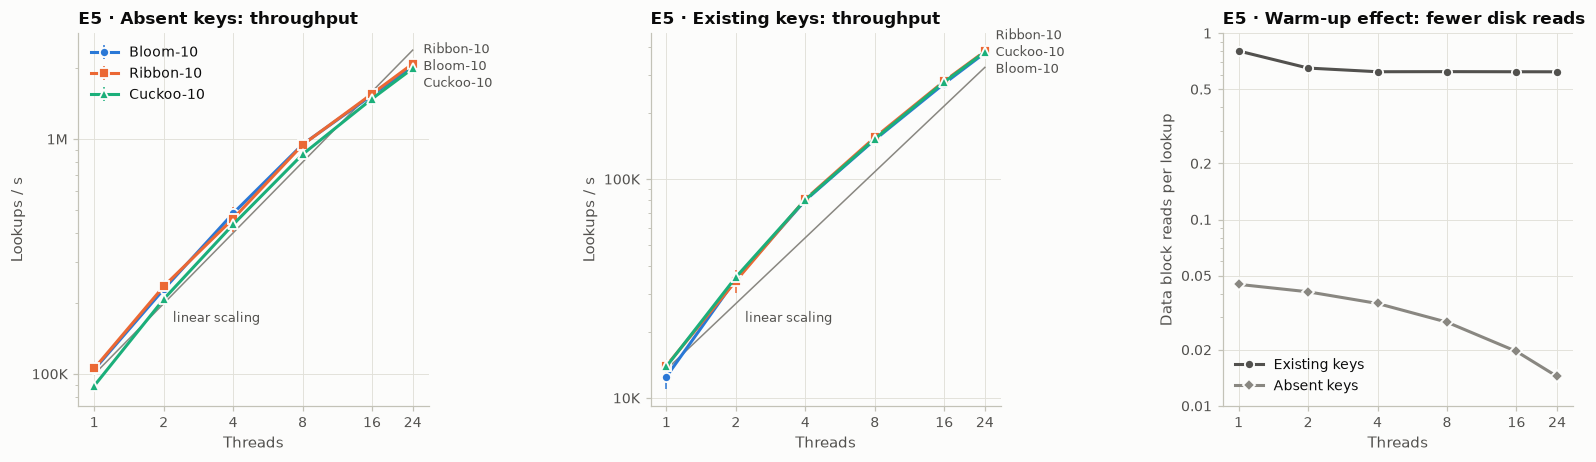

In [13]:
e5 = results[results["experiment"] == "E5_threads"]
e5s = summarize(e5, ["workload", "filter", "threads"], ["ops_per_sec", "data_misses_per_lookup"])
threads = sorted(e5s["threads"].unique())

fig, axes = plt.subplots(1, 3, figsize=(14.5, 4.3))
for ax, wl, title in zip(axes[:2], ("empty", "nonempty"), ("Absent keys", "Existing keys")):
    d = e5s[e5s["workload"] == wl]
    base = d[d["threads"] == 1]["ops_per_sec_mean"].mean()
    ax.plot(threads, [base * t for t in threads], color=MUTED, lw=1)
    ax.annotate("linear scaling", (threads[1], base * threads[1]), xytext=(6, -12),
                textcoords="offset points", ha="left", fontsize=8.5, color=INK2)
    ends = []
    for name in ("bloom-10", "ribbon-10", "cuckoo-10"):
        s = d[d["filter"] == name].sort_values("threads")
        plot_series(ax, s["threads"], s["ops_per_sec_mean"], s["ops_per_sec_std"], name,
                    label=E3_LABEL[name])
        ends.append((s["threads"].iloc[-1], s["ops_per_sec_mean"].iloc[-1], E3_LABEL[name]))
    ax.set_xscale("log", base=2)
    ax.set_yscale("log")
    ax.set_xticks(threads)
    ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{v:g}"))
    ax.xaxis.set_minor_locator(mticker.NullLocator())
    ax.yaxis.set_major_formatter(mticker.FuncFormatter(kfmt))
    ax.yaxis.set_minor_formatter(mticker.NullFormatter())
    ax.set_xlabel("Threads")
    ax.set_ylabel("Lookups / s")
    ax.set_title(f"E5 · {title}: throughput")
    label_ends(ax, ends)
axes[0].legend(loc="upper left")

# Warm-up effect, averaged over the three filters (workload is the series here,
# so it uses ink tones rather than filter colors)
ax = axes[2]
w = e5s.groupby(["workload", "threads"])["data_misses_per_lookup_mean"].mean().reset_index()
for wl, color, marker, label in (("nonempty", INK2, "o", "Existing keys"),
                                  ("empty", MUTED, "D", "Absent keys")):
    s = w[w["workload"] == wl]
    ax.plot(s["threads"], s["data_misses_per_lookup_mean"], color=color, marker=marker,
            markeredgecolor=SURFACE, markeredgewidth=1.2, label=label)
ax.set_xscale("log", base=2)
ax.set_yscale("log")
ax.set_xticks(threads)
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{v:g}"))
ax.xaxis.set_minor_locator(mticker.NullLocator())
ax.set_yticks([0.01, 0.02, 0.05, 0.1, 0.2, 0.5, 1])
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{v:g}"))
ax.yaxis.set_minor_formatter(mticker.NullFormatter())
ax.set_xlabel("Threads")
ax.set_ylabel("Data block reads per lookup")
ax.set_title("E5 · Warm-up effect: fewer disk reads")
ax.legend(loc="lower left")
fig.tight_layout(w_pad=6)
save(fig, "e5_thread_scaling")
plt.show()

display(e5s.pivot_table(index=["workload", "threads"], columns="filter", values="ops_per_sec_mean")
        .style.format("{:,.0f}").set_caption("E5 · mean lookups/s"))

## Findings (as of the 2026-10-23 run)

**TODO**

## Poke around

Helpers for interactive exploration. `results` has one row per run; `summarize`
averages repeats. Column meanings are in `README.md` (Output section).

In [14]:
def runs(**where):
    """Rows matching column=value filters, e.g. runs(filter="cuckoo-10", workload="empty")."""
    mask = pd.Series(True, index=results.index)
    for col, val in where.items():
        mask &= results[col].isin(val if isinstance(val, (list, tuple, set)) else [val])
    return results[mask]


def show_log(row, lines=40):
    """Print the end of the db_bench log for one result row (e.g. runs(...).iloc[0])."""
    path = RESULTS / row["log"]
    text = path.read_text().splitlines()
    print(f"{path}\n" + "\n".join(text[-lines:]))


# Examples:
summarize(runs(experiment="E2_memory_pressure", workload="nonempty"),
          ["filter", "cache_size"], ["ops_per_sec", "p99_us", "filter_misses_per_lookup"]).head(8)

,filter,cache_size,ops_per_sec_mean,p99_us_mean,filter_misses_per_lookup_mean,ops_per_sec_std,p99_us_std,filter_misses_per_lookup_std,n
0,bloom-10,33554432,6304.000000,561.950000,0.328552,392.309827,252.347306,0.000012,3
1,bloom-10,67108864,9890.333333,272.526667,0.032218,489.305971,57.992435,0.000006,3
2,bloom-10,134217728,11056.666667,197.986667,0.000065,31.533051,0.312143,0.000000,3
3,bloom-10,536870912,11965.333333,183.706667,0.000065,48.952358,2.017432,0.000000,3
4,cuckoo-10,33554432,6898.666667,370.706667,0.329672,49.217206,1.134739,0.000013,3
5,cuckoo-10,67108864,10090.666667,241.263333,0.032315,41.932485,0.413562,0.000005,3
6,cuckoo-10,134217728,10931.000000,219.430000,0.000065,50.239427,0.685493,0.000000,3
7,cuckoo-10,536870912,11798.666667,209.300000,0.000065,30.615900,0.825288,0.000000,3


In [15]:
# One configuration's repeats side by side, e.g. the noisiest one found above
runs(experiment="E3_empty_fraction", filter="bloom-16", workload="mixed-0.5")[
    ["repeat", "ops_per_sec", "p50_us", "p99_us", "fpr", "data_misses_per_lookup", "timestamp"]]

,repeat,ops_per_sec,p50_us,p99_us,fpr,data_misses_per_lookup,timestamp
136,1,12094,20.87,393.50,0.000785,0.481965,2026-10-23T13:36:58
143,2,22656,20.46,109.14,0.000785,0.481965,2026-10-23T13:39:19
150,3,22678,20.50,109.18,0.000785,0.481965,2026-10-23T13:41:36
